# Amazon Bestsellers: Exploratory Data Analysis (EDA)

This project analyzes a dataset of Amazon's Top 50 bestselling books. The primary goal is to uncover business insights regarding book popularity, pricing strategies, and user ratings across different genres (Fiction vs. Non-Fiction).

**Key Objectives:**
* Perform data cleaning and preprocessing.
* Analyze the distribution of book prices and user ratings.
* Identify top-performing authors and genre-specific trends using `Pandas`, `Matplotlib`, and `Seaborn`.

In [105]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [106]:
%matplotlib inline

In [107]:
df = pd.read_csv("bestsellers-with-categories_1_.csv")

In [108]:
display(df.head())

,Name,Author,User Rating,Reviews,Price,Year,Genre
0,10-Day Green Smoothie Cleanse,JJ Smith,4.7,17350,8,2016,Non Fiction
1,11/22/63: A Novel,Stephen King,4.6,2052,22,2011,Fiction
2,12 Rules for Life: An Antidote to Chaos,Jordan B. Peterson,4.7,18979,15,2018,Non Fiction
3,1984 (Signet Classics),George Orwell,4.7,21424,6,2017,Fiction
4,"5,000 Awesome Facts (About Everything!) (Natio...",National Geographic Kids,4.8,7665,12,2019,Non Fiction


In [109]:
print(f"Dataset shape: {df.shape}")

Dataset shape: (550, 7)


In [110]:
df.columns = ['name', 'author', 'user_rating', 'reviews', 'price', 'year', 'genre']

In [111]:
print(df.isna().sum()) # Checking for missing values in the dataset

name           0
author         0
user_rating    0
reviews        0
price          0
year           0
genre          0
dtype: int64


In [112]:
print(df['genre'].unique())

['Non Fiction' 'Fiction']


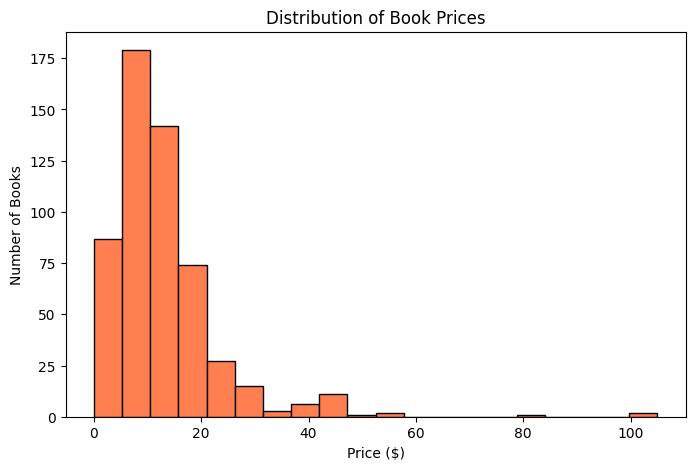

In [113]:
df['price'].plot(kind='hist', bins=20, color='coral', edgecolor='black', figsize=(8, 5))
plt.title('Distribution of Book Prices')
plt.xlabel('Price ($)')
plt.ylabel('Number of Books')
plt.show()

In [114]:
max_price = df['price'].max()
min_price = df['price'].min()
mean_price = df['price'].mean()
median_price = df['price'].median()

In [115]:
print(f"Max: {max_price}, Min: {min_price}, Mean: {mean_price:.2f}, Median: {median_price}")

Max: 105, Min: 0, Mean: 13.10, Median: 11.0


In [116]:
max_rating = df['user_rating'].max()
print(f"Highest user rating: {max_rating}")

Highest user rating: 4.9


In [117]:
books_with_max_rating = len(df[df['user_rating'] == max_rating])
print(f"Number of books with the highest rating: {books_with_max_rating}")

Number of books with the highest rating: 52


In [118]:
max_reviews_index = df['reviews'].idxmax()
best_reviewed_book = df.loc[max_reviews_index, 'name']
print(f"Book with the most reviews: {best_reviewed_book}")

Book with the most reviews: Where the Crawdads Sing


In [119]:
df_2015 = df[df['year'] == 2015]
most_expensive_2015 = df_2015.loc[df_2015['price'].idxmax(), 'name']
print(f"Most expensive book in 2015: {most_expensive_2015}")

Most expensive book in 2015: Publication Manual of the American Psychological Association, 6th Edition


In [120]:
fiction_2010 = len(df[(df['genre'] == 'Fiction') & (df['year'] == 2010)])
print(f"Number of Fiction books in 2010: {fiction_2010}")

Number of Fiction books in 2010: 20


In [121]:
top_rated_10_11 = len(df[(df['user_rating'] == 4.9) & (df['year'].isin([2010, 2011]))])
print(f"Books with a 4.9 rating in 2010-2011: {top_rated_10_11}")

Books with a 4.9 rating in 2010-2011: 1


In [122]:
cheap_2015 = df[(df['year'] == 2015) & (df['price'] < 8)].sort_values(by='price')

In [123]:
last_book = cheap_2015.iloc[-1]['name']
print(f"Last book in the sorted list (price < $8 in 2015): {last_book}")

Last book in the sorted list (price < $8 in 2015): Old School (Diary of a Wimpy Kid #10)


In [124]:
genre_prices = df.groupby('genre').agg({'price': ['min', 'max']})
display(genre_prices)

price     
              min  max
genre                 
Fiction         0   82
Non Fiction     0  105

In [125]:
author_books_count = df.groupby('author').agg({'name': 'count'})

In [126]:
author_books_count = author_books_count.rename(columns={'name': 'books_count'})

In [127]:
print(author_books_count.shape)

(248, 1)


In [128]:
top_author = author_books_count['books_count'].idxmax()
top_author_count = author_books_count['books_count'].max()
print(f"Author with the most books: {top_author} ({top_author_count} books)")

Author with the most books: Jeff Kinney (12 books)


In [129]:
author_avg_rating = df.groupby('author').agg({'user_rating': 'mean'})

In [130]:
author_avg_rating = author_avg_rating.rename(columns={'user_rating': 'avg_rating'})

In [131]:
worst_author = author_avg_rating['avg_rating'].idxmin()
worst_author_rating = author_avg_rating['avg_rating'].min()
print(f"\nAuthor with the lowest average rating: {worst_author} (rating {worst_author_rating})")


Author with the lowest average rating: Donna Tartt (rating 3.9)


In [132]:
author_stats = pd.concat([author_books_count, author_avg_rating], axis=1)

In [133]:
author_stats_sorted = author_stats.sort_values(by=['books_count', 'avg_rating'])

In [134]:
print("\nTop authors sorted by book count and average rating:")
display(author_stats_sorted.head())


Top authors sorted by book count and average rating:


,books_count,avg_rating
author,,
Muriel Barbery,1,4.0
Chris Cleave,1,4.1
Ian K. Smith M.D.,1,4.1
Pierre Dukan,1,4.1
Elizabeth Strout,1,4.2


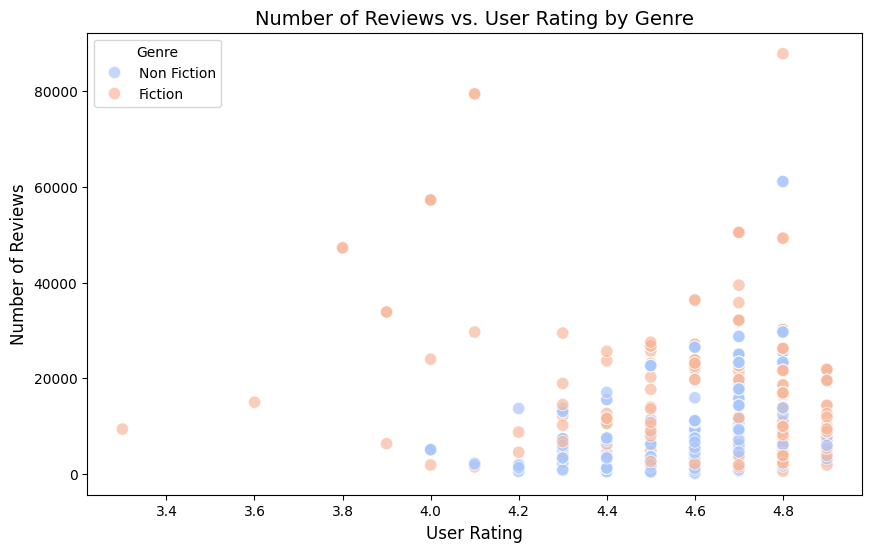

In [135]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x='user_rating', y='reviews', hue='genre', data=df, palette='coolwarm', alpha=0.7, s=80)
plt.title('Number of Reviews vs. User Rating by Genre', fontsize=14)
plt.xlabel('User Rating', fontsize=12)
plt.ylabel('Number of Reviews', fontsize=12)
plt.legend(title='Genre')
plt.show()

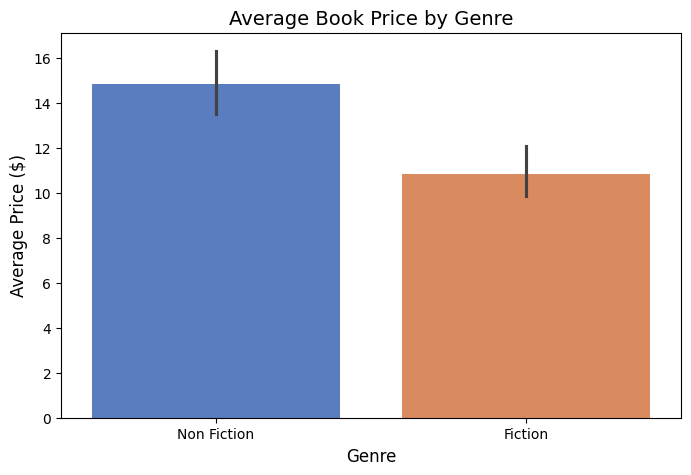

In [136]:
plt.figure(figsize=(8, 5))
sns.barplot(x='genre', y='price', data=df, palette='muted', hue='genre', legend=False)
plt.title('Average Book Price by Genre', fontsize=14)
plt.xlabel('Genre', fontsize=12)
plt.ylabel('Average Price ($)', fontsize=12)
plt.show()

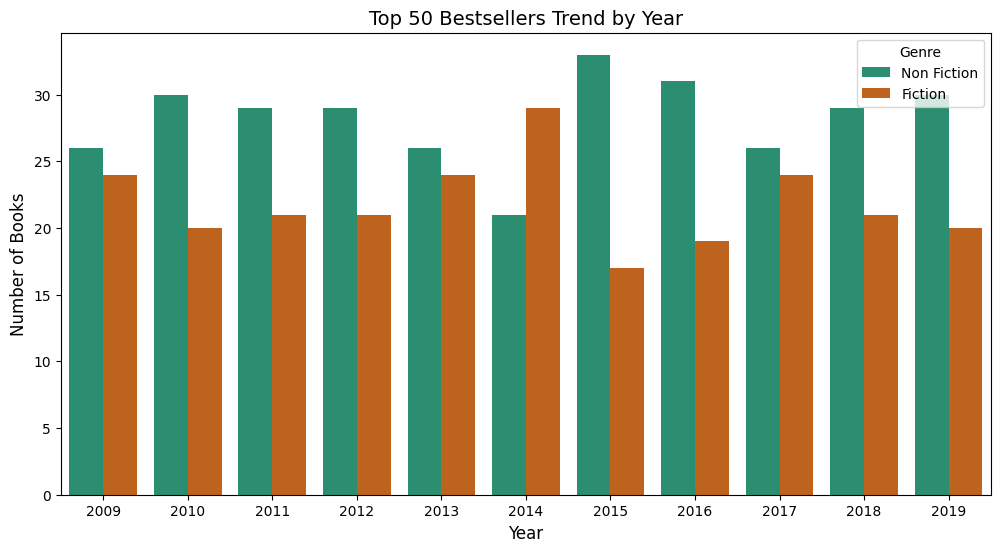

In [137]:
plt.figure(figsize=(12, 6))
sns.countplot(x='year', hue='genre', data=df, palette='Dark2')
plt.title('Top 50 Bestsellers Trend by Year', fontsize=14)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Number of Books', fontsize=12)
plt.legend(title='Genre')
plt.show()